In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import sys, os, sqlite3

sys.path.insert(0, os.path.join(os.getcwd(), '..'))
from framework import init_env
init_env()

path = os.path.join("..", os.environ["DB_FILE"])
database = sqlite3.connect(path)

Selecteer de 10 populairste artiesten van de gegeven editie

In [2]:
edition = 2025

sql = f"""
    SELECT artistid, name, SUM(popularity) AS popularity
    FROM (
        SELECT A.rowid AS artistid, A.name, (2001 - position) as popularity
        FROM Occurance O
        INNER JOIN Song S ON S.rowid = O.song
        INNER JOIN Artist A ON A.rowid = S.artist
        WHERE edition = {edition}
        ORDER BY position
        )
    GROUP BY artistid, name
    ORDER BY popularity DESC
    LIMIT 10
"""
df = pd.read_sql_query(sql, database)
df

,artistid,name,popularity
0,1295,Queen,35190
1,8,ABBA,31256
2,1564,The Beatles,27320
3,531,Fleetwood Mac,25848
4,229,Bruce Springsteen,25420
5,1083,Michael Jackson,20935
6,1699,U2,20792
7,313,Coldplay,20657
8,1277,Pink Floyd,20579
9,416,Dire Straits,20341


In [3]:
top10_score = sum(df["popularity"])
total_score = sum(range(2002))
top10_score / total_score * 100

12.398296356317346

In [4]:
artists = list(df['artistid'])
artist_ids = ",".join(str(a) for a in artists)

Populariteit van een artiest vanaf begin tot aan `edition`

In [5]:
sql = f"""
    SELECT artistid, name, edition, SUM(song_popularity) AS popularity
    FROM (
        SELECT S.artist AS artistid, A.name, O.edition, (2001 - position) as song_popularity
        FROM Occurance O
        INNER JOIN Song S ON S.rowid = O.song
        INNER JOIN Artist A ON A.rowid = S.artist
        WHERE S.artist IN ({artist_ids})
        AND O.edition <= {edition}
        )
    GROUP BY artistid, name, edition
    ORDER BY edition, popularity DESC
"""
df = pd.read_sql_query(sql, database)
df

,artistid,name,edition,popularity
0,1564,The Beatles,1999,58149
1,8,ABBA,1999,23558
2,1295,Queen,1999,19622
3,1083,Michael Jackson,1999,12749
4,531,Fleetwood Mac,1999,12266
...,...,...,...,...
261,1083,Michael Jackson,2025,20935
262,1699,U2,2025,20792
263,313,Coldplay,2025,20657
264,1277,Pink Floyd,2025,20579


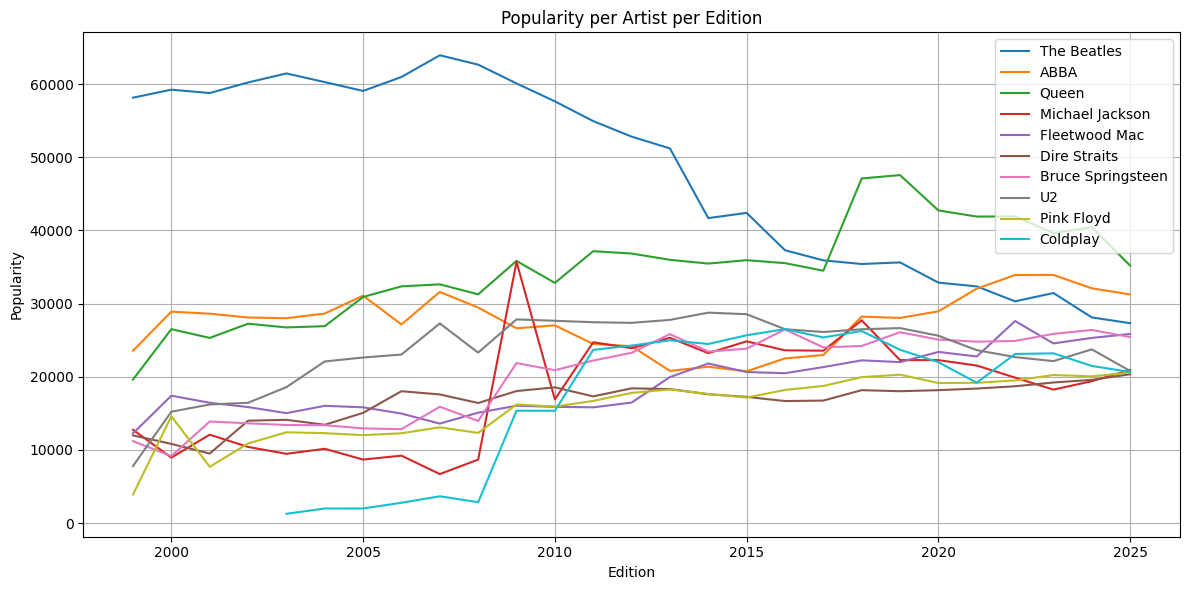

In [6]:
import matplotlib.pyplot as plt

# Zorg ervoor dat 'edition' numeriek is (voor de x-as)
df['edition'] = pd.to_numeric(df['edition'])

# Maak de plot
plt.figure(figsize=(12, 6))

# Plot een lijn voor elke artiest
for artist in df['name'].unique():
    artist_data = df[df['name'] == artist]
    plt.plot(artist_data['edition'], artist_data['popularity'], label=artist)

plt.xlabel('Edition')
plt.ylabel('Popularity')
plt.title('Popularity per Artist per Edition')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
